# Лабораторная работа №1

Номер по списку: **10**, ПК: **10**, группа: **2**.

Варианты таблиц выбираются по кругу: (номер−1) % число строк + 1. Для ЛР3–4 N=ПК+группа; N не является номером по списку.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats, special
import pywt
plt.rcParams.update({'figure.figsize': (12,4), 'figure.dpi': 100,
                     'axes.grid': True, 'grid.alpha': .25})
number=10; pc=10; group=2
rng=np.random.default_rng(1010)


## Равномерная и нормальная случайные величины
Конгруэнтный генератор: $s_{k+1}=(1664525s_k+1013904223)\bmod 2^{32}$, $U=(s+0.5)/2^{32}$.
Нормальная СВ получается произведением независимых релеевской и арксинусной СВ:
$Z_1=\sqrt{-2\ln U_1}\cos(2\pi U_2)$, $Z_2=\sqrt{-2\ln U_1}\sin(2\pi U_2)$; $X=\mu+\sigma Z$.
Здесь $\sigma=2$, $\mu=a=\lambda=10$; $Z_1,Z_2$ стандартные нормальные.
Структура: **LCG → U₁,U₂ → радиус и фаза → Z₁,Z₂ → μ+σZ → X**.
Нормировка гистограмм: $\hat p(x_i)=n_i/(N\Delta x_i)$; аналитическая плотность рассчитывается в центрах интервалов.

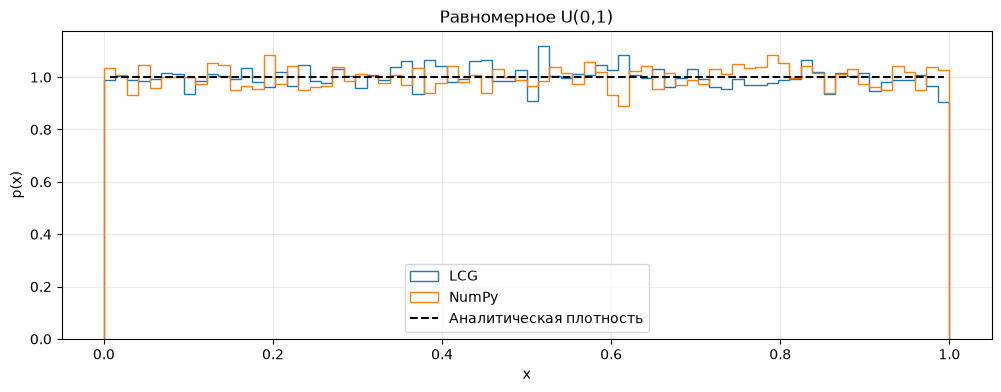

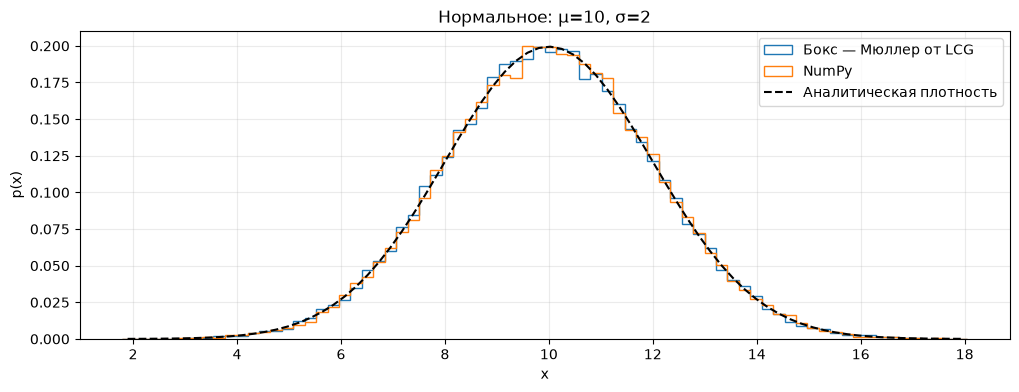

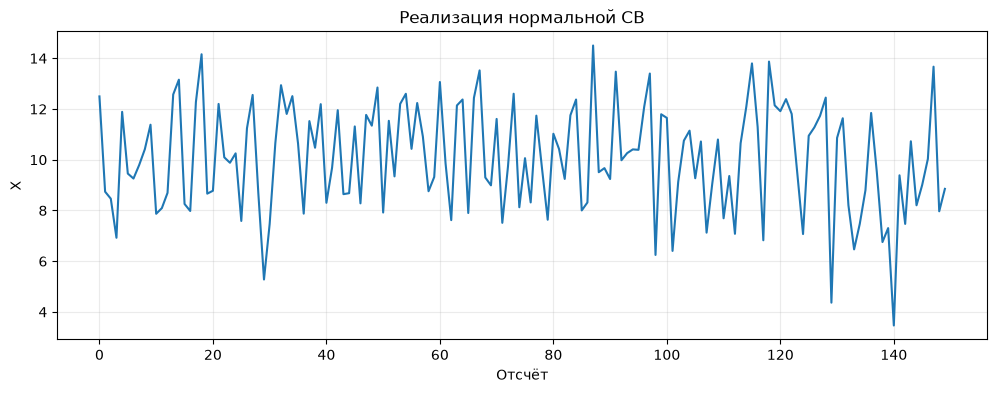

Оценки нормальной СВ: среднее, дисперсия: 9.988623088423973 3.999663810901081 ; теория: 10 4
Корреляция Z1,Z2: 0.004337914491246696


In [2]:
size=50000; sigma=group; mu=number
state=123456789
u=np.empty(2*size)
for k in range(len(u)):
    state=(1664525*state+1013904223) % 2**32
    u[k]=(state+.5)/2**32
u1,u2=u[::2],u[1::2]
r=np.sqrt(-2*np.log(u1)); phase=2*np.pi*u2
z1,z2=r*np.cos(phase),r*np.sin(phase)
x=mu+sigma*z1
xlib=rng.normal(mu,sigma,size)
def compare(samples,labels,dist,title):
    edges=np.linspace(min(s.min() for s in samples),max(s.max() for s in samples),75)
    centers=(edges[1:]+edges[:-1])/2
    fig,ax=plt.subplots()
    for s,l in zip(samples,labels): ax.hist(s,bins=edges,density=True,histtype='step',label=l)
    ax.plot(centers,dist.pdf(centers),'k--',label='Аналитическая плотность')
    ax.set(xlabel='x',ylabel='p(x)',title=title); ax.legend(); plt.show()
compare([u1,rng.uniform(size=size)],['LCG','NumPy'],stats.uniform(),'Равномерное U(0,1)')
compare([x,xlib],['Бокс — Мюллер от LCG','NumPy'],stats.norm(mu,sigma),f'Нормальное: μ={mu}, σ={sigma}')
fig,ax=plt.subplots(); ax.plot(x[:150]); ax.set(xlabel='Отсчёт',ylabel='X',title='Реализация нормальной СВ'); plt.show()
print('Оценки нормальной СВ: среднее, дисперсия:',x.mean(),x.var(),'; теория:',mu,sigma**2)
print('Корреляция Z1,Z2:',np.corrcoef(z1,z2)[0,1])

## Вариант 2: нормальное → Райса
$$Y=\sqrt{(\sigma Z_1+a)^2+(\sigma Z_2)^2}.$$
Структура: **Z₁,Z₂ → нелинейное преобразование → Y → гистограмма и моменты**.

Для Райса $a=10$, $\sigma=2$, $b=a/\sigma=5$.
$$p(y)=\frac{y}{\sigma^2}\exp\left(-\frac{y^2+a^2}{2\sigma^2}\right)I_0(ay/\sigma^2),\quad y\ge0.$$
Параметр `loc` равен нулю: смещение a действует на одну квадратуру, а не на итоговую амплитуду.

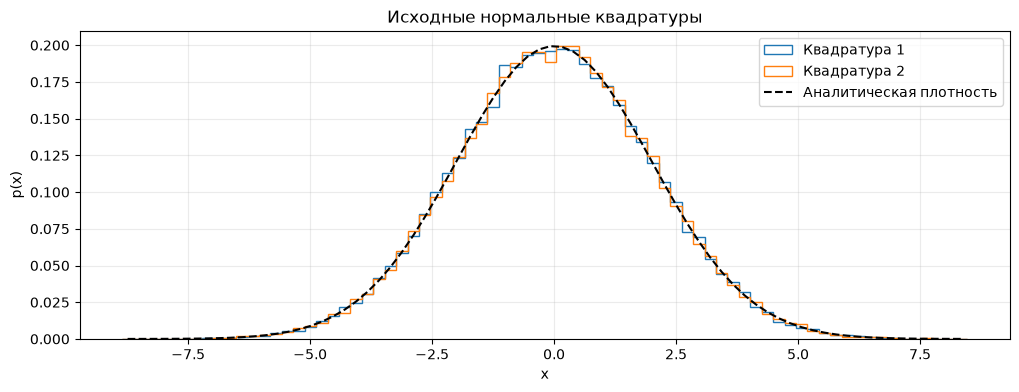

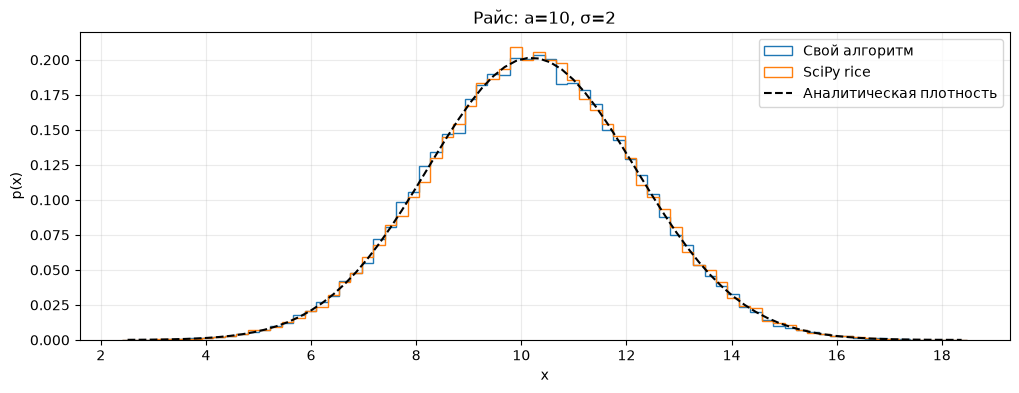

In [3]:
y=np.hypot(sigma*z1+number,sigma*z2)
dist=stats.rice(number/sigma,scale=sigma)
ylib=dist.rvs(size=size,random_state=rng)
compare([sigma*z1,sigma*z2],['Квадратура 1','Квадратура 2'],stats.norm(0,sigma),'Исходные нормальные квадратуры')
compare([y,ylib],['Свой алгоритм','SciPy rice'],dist,f'Райс: a={number}, σ={sigma}')

Y: среднее / теория: 10.190567917428195 10.20213927898425
Y: дисперсия / теория: 3.9247781252403615 3.9163541322067346


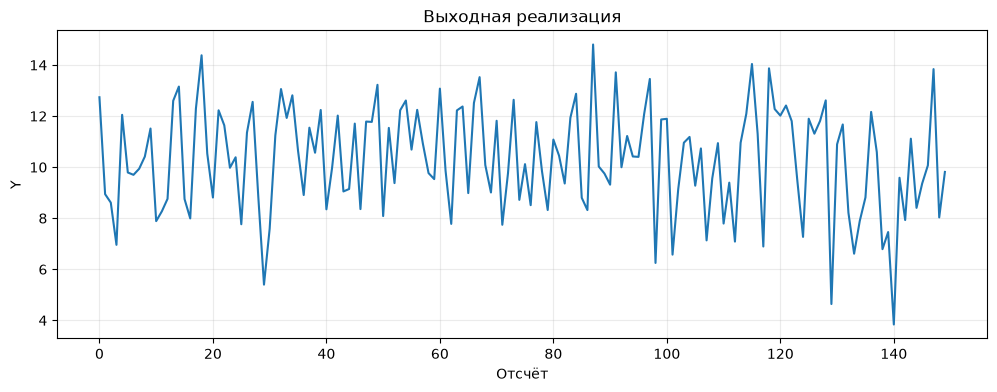

In [4]:
print('Y: среднее / теория:',y.mean(),dist.mean())
print('Y: дисперсия / теория:',y.var(),dist.var())
fig,ax=plt.subplots(); ax.plot(y[:150]); ax.set(xlabel='Отсчёт',ylabel='Y',title='Выходная реализация'); plt.show()

## Выводы
Получены равномерная, нормальная и райса СВ; собственные алгоритмы сопоставлены с библиотечными и аналитической плотностью. Оценки моментов приведены выше, конечная выборка вызывает отклонения гистограмм от теории. Псевдослучайный LCG детерминирован, поэтому совпадение плотности само по себе не доказывает независимость.
Распределение Райса описывает амплитуду узкополосного сигнала на фоне гауссовского шума: одна квадратура содержит детерминированную составляющую a.